#### Import Main Libraries Load Dataset

In [3]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Visualization Settings
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('Amazon_Unlocked_Mobile.csv')

#### Data Understanding


In [4]:
df.head()

,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


In [5]:
df.tail()

,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
413835,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,5,another great deal great price,0.0
413836,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,3,Ok,0.0
413837,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,5,Passes every drop test onto porcelain tile!,0.0
413838,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,3,I returned it because it did not meet my needs...,0.0
413839,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,4,Only downside is that apparently Verizon no lo...,0.0


In [6]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 413840
Total Columns: 6


In [7]:
df.columns

Index(['Product Name', 'Brand Name', 'Price', 'Rating', 'Reviews',
       'Review Votes'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413840 entries, 0 to 413839
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Product Name  413840 non-null  object 
 1   Brand Name    348669 non-null  object 
 2   Price         407907 non-null  float64
 3   Rating        413840 non-null  int64  
 4   Reviews       413770 non-null  object 
 5   Review Votes  401544 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 18.9+ MB


In [9]:
df.describe(include='all')

,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
count,413840,348669,407907.000000,413840.000000,413770,401544.000000
unique,4410,384,NaN,NaN,162490,NaN
top,Apple iPhone 4s 8GB Unlocked Smartphone w/ 8MP...,Samsung,NaN,NaN,Good,NaN
freq,1451,65747,NaN,NaN,2879,NaN
mean,NaN,NaN,226.867155,3.819578,NaN,1.507237
std,NaN,NaN,273.006259,1.548216,NaN,9.163853
min,NaN,NaN,1.730000,1.000000,NaN,0.000000
25%,NaN,NaN,79.990000,3.000000,NaN,0.000000
50%,NaN,NaN,144.710000,5.000000,NaN,0.000000
75%,NaN,NaN,269.990000,5.000000,NaN,1.000000


In [10]:
df.isnull().sum()

Product Name        0
Brand Name      65171
Price            5933
Rating              0
Reviews            70
Review Votes    12296
dtype: int64

In [11]:
(df.isnull().sum() / len(df)) * 100

Product Name     0.000000
Brand Name      15.747874
Price            1.433646
Rating           0.000000
Reviews          0.016915
Review Votes     2.971197
dtype: float64

In [12]:
df.duplicated().sum()

np.int64(64079)

In [13]:
print("Total Brands:", df['Brand Name'].nunique())

Total Brands: 384


In [14]:
print("Total Products:", df['Product Name'].nunique())

Total Products: 4410


####  Data Cleaning

In [15]:
data = df.copy()

In [16]:
data.drop_duplicates(inplace=True)

In [17]:
# Remove records with missing review text
data.dropna(subset=['Reviews'], inplace=True)

In [18]:
# Remove missing product nameS
data.dropna(subset=['Product Name'], inplace=True)

In [20]:
# Handle missing brand names
data['Brand Name'] = data['Brand Name'].fillna('Unknown')

In [21]:
# Handle missing prices
data['Price'] = pd.to_numeric(data['Price'], errors='coerce')

In [23]:
# Handle missing ratings
data['Rating'] = pd.to_numeric(data['Rating'], errors='coerce')

data = data[data['Rating'].between(1, 5)]

In [25]:
# Clean review text
data['Reviews'] = data['Reviews'].astype(str).str.strip()

data = data[data['Reviews'] != '']

In [26]:
# Final dataset inspection
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", data.shape)

display(data.isnull().sum())

Original Dataset: (413840, 6)
Cleaned Dataset: (349704, 6)


Product Name        0
Brand Name          0
Price            5234
Rating              0
Reviews             0
Review Votes    12274
dtype: int64

#### Exploratory Data Analysis (EDA)

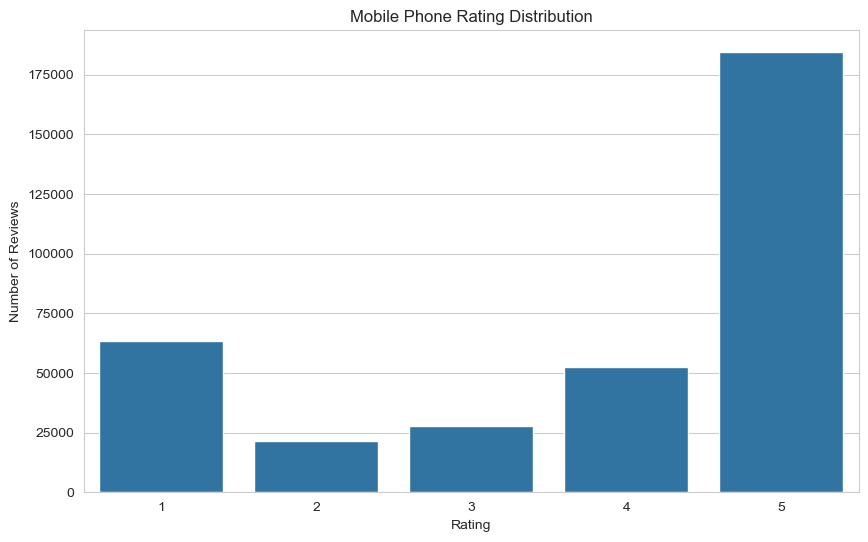

In [27]:
# 5.1 Rating distribution
sns.countplot(data=data, x='Rating')

plt.title('Mobile Phone Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.show()

In [29]:
# 5.2 Average rating
print("Average Rating:", data['Rating'].mean())

Average Rating: 3.781460892640633


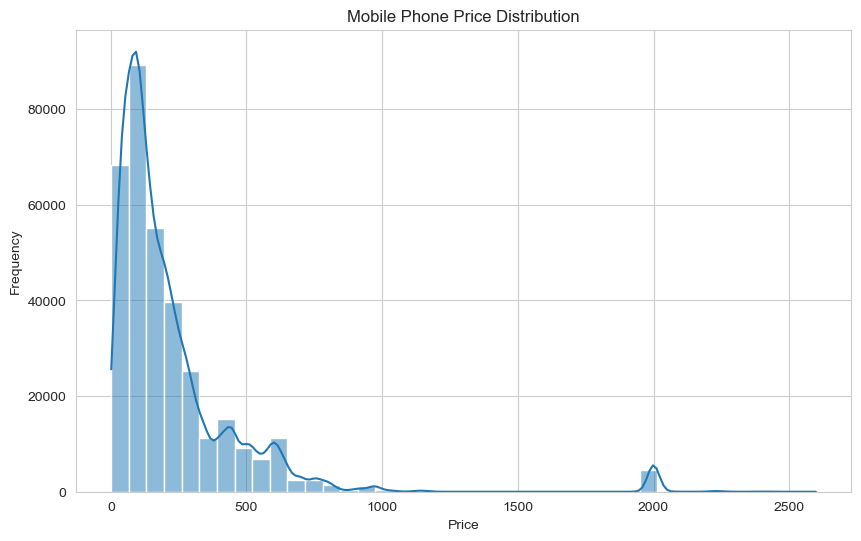

In [31]:
# Price distribution
sns.histplot(data['Price'].dropna(), bins=40, kde=True)

plt.title('Mobile Phone Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

#### Rating percentage


In [32]:
rating_percentage = data['Rating'].value_counts(normalize=True) * 100

display(rating_percentage.sort_index())

Rating
1    18.117036
2     6.160639
3     7.916409
4    15.071032
5    52.734884
Name: proportion, dtype: float64

#### Review length analysis

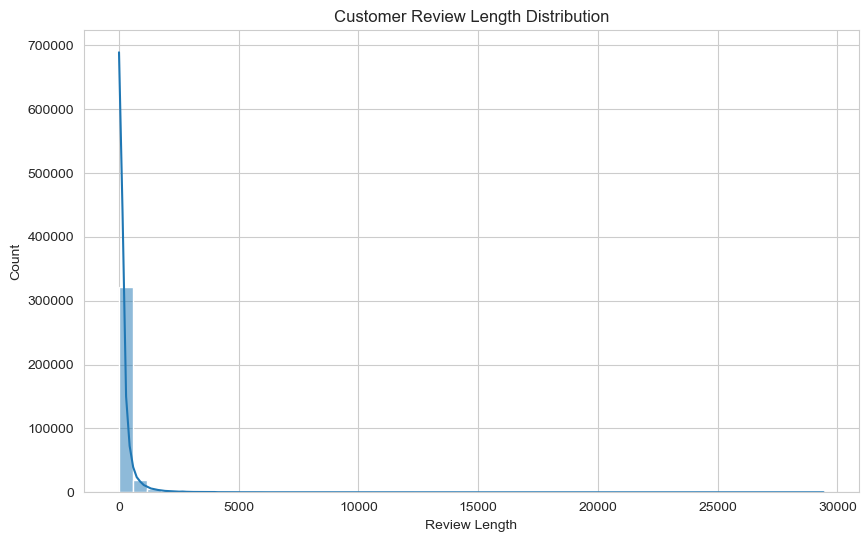

In [33]:
data['Review_Length'] = data['Reviews'].apply(len)

sns.histplot(data['Review_Length'], bins=50, kde=True)

plt.title('Customer Review Length Distribution')
plt.xlabel('Review Length')
plt.show()

#### Brand Analysis

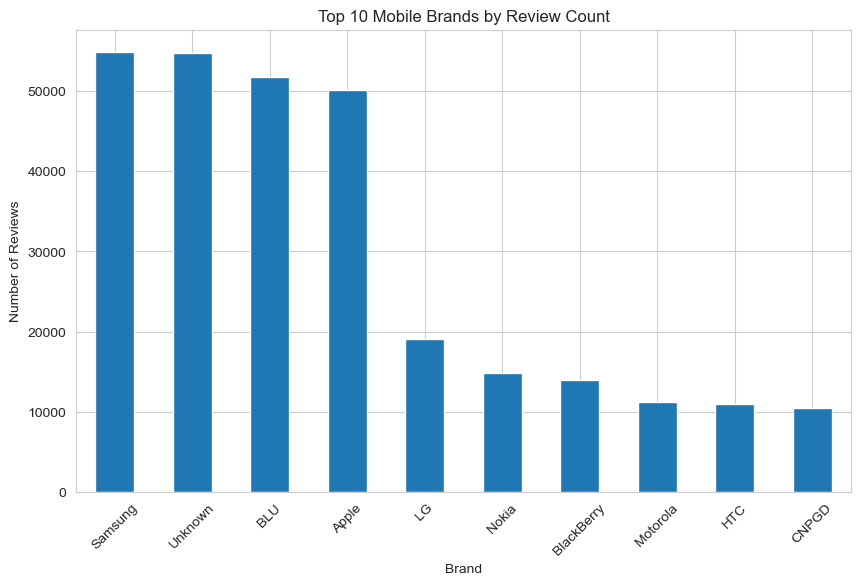

In [34]:
top_brands = data['Brand Name'].value_counts().head(10)

top_brands.plot(kind='bar')

plt.title('Top 10 Mobile Brands by Review Count')
plt.xlabel('Brand')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.show()

#### Average rating by brand

In [35]:
brand_ratings = (
    data.groupby('Brand Name')['Rating']
    .mean()
    .sort_values(ascending=False)
)

display(brand_ratings.head(15))

Brand Name
iPartsBuy                5.0
iNew                     5.0
Bluboo                   5.0
TracFone                 5.0
VIP                      5.0
S7 active                5.0
SONY ERICSSON            5.0
Seawolf Technologies     5.0
Spicy World              5.0
RomaCostume              5.0
Samsung International    5.0
Saliency                 5.0
H2O                      5.0
MICROSOFT                5.0
LeEco                    5.0
Name: Rating, dtype: float64

#### Brand-wise review count and average rating

In [36]:
brand_analysis = data.groupby('Brand Name').agg(
    Total_Reviews=('Rating', 'count'),
    Average_Rating=('Rating', 'mean'),
    Average_Price=('Price', 'mean')
).reset_index()

brand_analysis.sort_values(
    by='Total_Reviews',
    ascending=False
).head(15)

,Brand Name,Total_Reviews,Average_Rating,Average_Price
252,Samsung,54915,3.915123,290.096603
312,Unknown,54809,3.806327,251.939233
19,BLU,51815,3.740770,261.968745
14,Apple,50128,3.899996,303.464492
151,LG,19107,3.794630,204.797822
191,Nokia,14848,3.799636,154.951968
22,BlackBerry,13924,3.664895,91.598007
183,Motorola,11239,3.762345,149.776469
108,HTC,10984,3.430171,163.381993
41,CNPGD,10444,3.082631,52.009245


#### Product Analysis

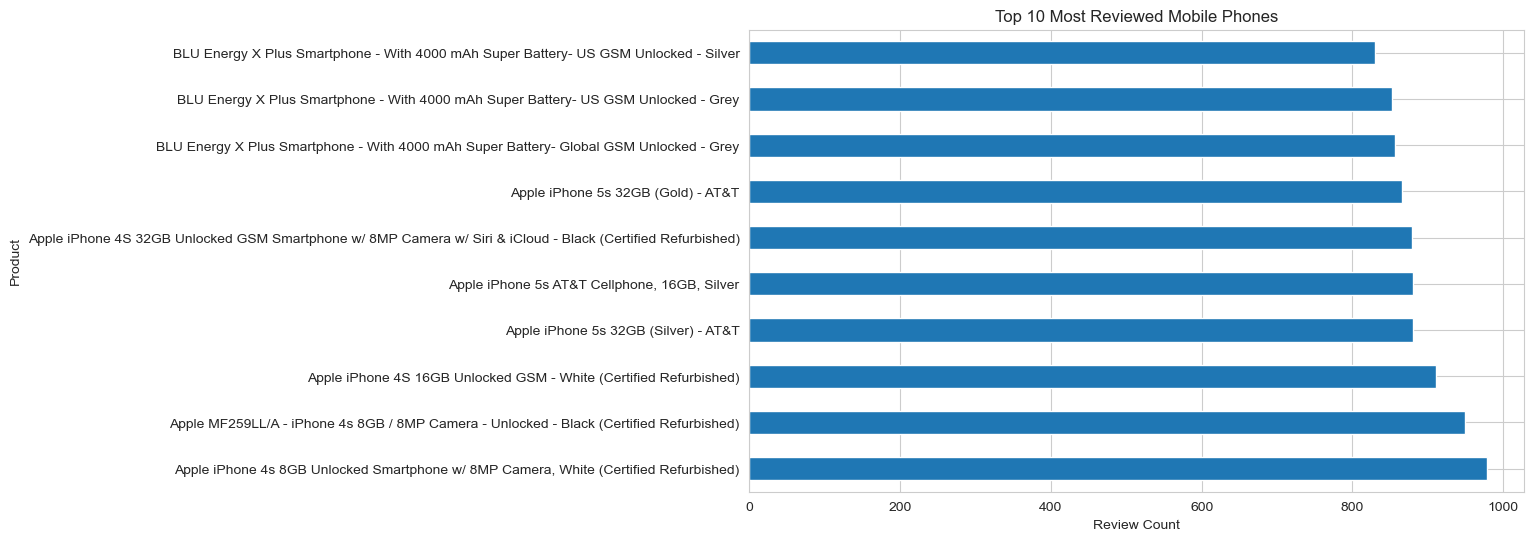

In [37]:
# 7.1 Top 10 products by review count
top_products = data['Product Name'].value_counts().head(10)

top_products.plot(kind='barh')

plt.title('Top 10 Most Reviewed Mobile Phones')
plt.xlabel('Review Count')
plt.ylabel('Product')
plt.show()

#### Average rating by product

In [38]:
product_ratings = data.groupby('Product Name').agg(
    Average_Rating=('Rating', 'mean'),
    Total_Reviews=('Rating', 'count'),
    Average_Price=('Price', 'mean')
).reset_index()

product_ratings.sort_values(
    by='Average_Rating',
    ascending=False
).head(20)

,Product Name,Average_Rating,Total_Reviews,Average_Price
9,2016 Latest Mini6 Small Android 5.1 Smart Mobi...,5.0,1,79.95
4355,iNew U9 Plus 16GB 6.0 Inch Android 5.1 Smartph...,5.0,2,115.99
4354,iNew U9 Plus 16GB 6.0 Inch Android 5.1 Smartph...,5.0,2,115.99
4353,iNew U9 Plus 16GB 6.0 Inch Android 5.1 Smartph...,5.0,2,115.99
17,4G Huawei Honor 6 Plus PE-UL00 FNC 3GB+16GB 5....,5.0,2,228.00
920,BlackBerry PRD-42113-004 Unlocked Porsche Desi...,5.0,2,394.98
944,BlackBerry Torch 9860 Unlocked 3G GSM Phone wi...,5.0,1,190.00
950,Blackberry 8310,5.0,2,16.79
963,Blackberry Curve 3G 9300 Unlocked GSM Phone wi...,5.0,2,79.00
1013,Blackberry Torch 9810 8GB Unlocked GSM 4G HSPA...,5.0,1,83.72


#### NLP Text Preprocessing

In [39]:
import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [40]:
# Download required resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...


True

### 

In [42]:
# Initialize tools
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

In [43]:
# Create text cleaning function
def clean_text(text):

    text = text.lower()

    text = re.sub(r'http\S+|www\S+', '', text)

    text = re.sub(r'<.*?>', '', text)

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    tokens = word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return ' '.join(tokens)

In [44]:
#  Apply text preprocessing
data['Clean_Reviews'] = data['Reviews'].apply(clean_text)

In [45]:
# Display original and cleaned reviews
data[['Reviews', 'Clean_Reviews']].head(10)

,Reviews,Clean_Reviews
0,I feel so LUCKY to have found this used (phone...,feel lucky found used phone used hard phone li...
1,"nice phone, nice up grade from my pantach revu...",nice phone nice grade pantach revue clean set ...
2,Very pleased,pleased
3,It works good but it goes slow sometimes but i...,work good go slow sometimes good phone love
4,Great phone to replace my lost phone. The only...,great phone replace lost phone thing volume bu...
5,I already had a phone with problems... I know ...,already phone problem know stated used dang st...
6,The charging port was loose. I got that solder...,charging port loose got soldered needed new ba...
7,"Phone looks good but wouldn't stay charged, ha...",phone look good wouldnt stay charged buy new b...
8,I originally was using the Samsung S2 Galaxy f...,originally using samsung galaxy sprint wanted ...
9,It's battery life is great. It's very responsi...,battery life great responsive touch issue some...


In [46]:
""" In a production NLP pipeline, we should preserve negation words such as not, never, and no.
Before final model training, we'll adjust the stopword list so that negative expressions aren't 
accidentally removed."""

" In a production NLP pipeline, we should preserve negation words such as not, never, and no.\nBefore final model training, we'll adjust the stopword list so that negative expressions aren't \naccidentally removed."

#### Text Exploration

In [47]:
from collections import Counter

all_words = ' '.join(data['Clean_Reviews'])

word_frequency = Counter(all_words.split())

word_frequency.most_common(20)

[('phone', 413545),
 ('great', 87997),
 ('good', 84132),
 ('work', 79142),
 ('one', 58987),
 ('like', 55271),
 ('screen', 52677),
 ('use', 49428),
 ('battery', 48486),
 ('get', 46166),
 ('love', 45572),
 ('would', 42271),
 ('time', 40150),
 ('new', 38959),
 ('camera', 33496),
 ('product', 32669),
 ('really', 32576),
 ('price', 31596),
 ('problem', 30909),
 ('dont', 30336)]

In [50]:
pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


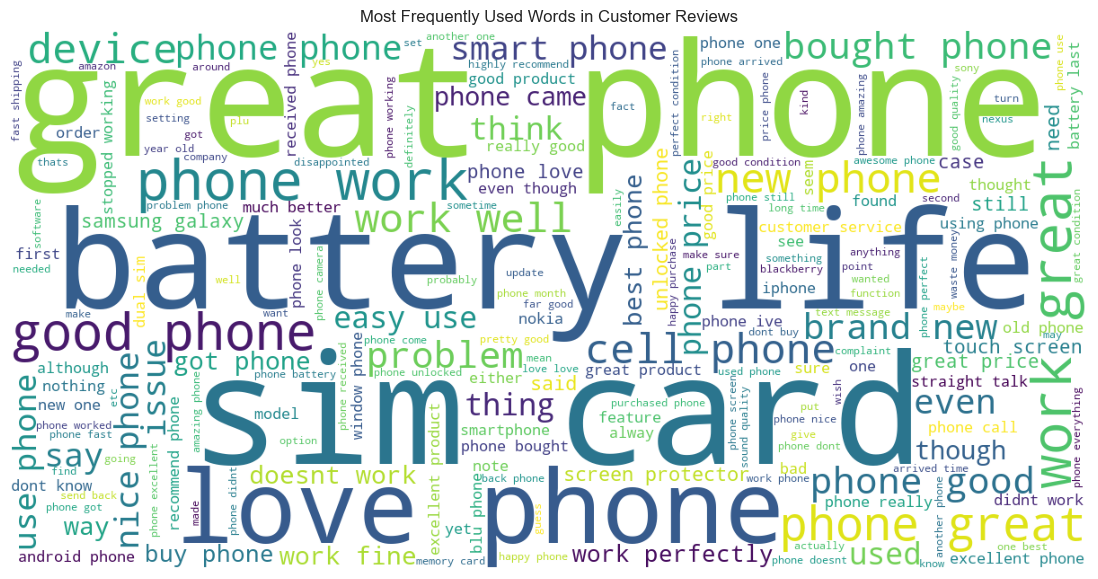

In [51]:
# WordCloud
from wordcloud import WordCloud

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white'
).generate(all_words)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud)
plt.axis('off')
plt.title('Most Frequently Used Words in Customer Reviews')
plt.show()

#### Sentiment Analysis

In [52]:
# We will initially use customer ratings to generate sentiment labels
def sentiment_label(rating):

    if rating <= 2:
        return 'Negative'

    elif rating == 3:
        return 'Neutral'

    else:
        return 'Positive'

In [53]:
data['Sentiment'] = data['Rating'].apply(sentiment_label)

#### Sentiment distribution

In [54]:
data['Sentiment'].value_counts()

Sentiment
Positive    237120
Negative     84900
Neutral      27684
Name: count, dtype: int64

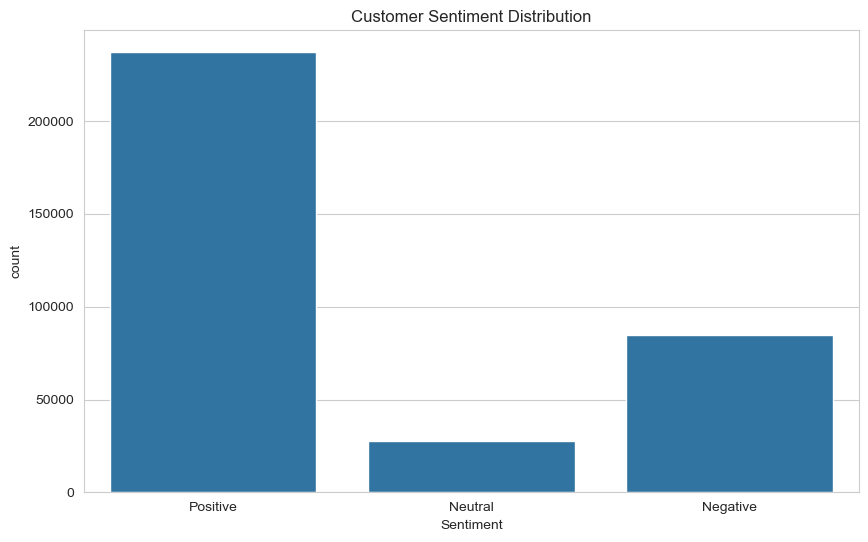

In [56]:
# Sentiment visualization 
sns.countplot(
    data=data,
    x='Sentiment',
    order=['Positive', 'Neutral', 'Negative']
)

plt.title('Customer Sentiment Distribution')
plt.show()

### Machine Learning Model Building

In [58]:
# Now we import Scikit-learn model-building libraries.
from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

#### Model Evaluation

In [62]:
# Separate features and target
X = data['Clean_Reviews']
y = data['Sentiment']

In [63]:
# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [65]:
# TF-IDF Vectorization
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=3,
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [66]:
# Verify the shapes
print("X_train:", X_train_tfidf.shape)
print("X_test:", X_test_tfidf.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (279763, 10000)
X_test: (69941, 10000)
y_train: (279763,)
y_test: (69941,)


In [67]:
# First, let's train and compare our three models
# Initialize models

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Naive Bayes': MultinomialNB(),
    'Linear SVM': LinearSVC(class_weight='balanced')
}

# Train models

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train_tfidf, y_train)

    trained_models[name] = model

print("All models trained successfully!")

Training Logistic Regression...
Training Naive Bayes...
Training Linear SVM...
All models trained successfully!


In [68]:
# Compare model performance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_tfidf)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1 Score': f1_score(y_test, y_pred, average='weighted')
    })

model_results = pd.DataFrame(results)

display(model_results.sort_values(by='F1 Score', ascending=False))

,Model,Accuracy,Precision,Recall,F1 Score
2,Linear SVM,0.860883,0.864723,0.860883,0.862692
0,Logistic Regression,0.808982,0.873117,0.808982,0.832426
1,Naive Bayes,0.842939,0.813310,0.842939,0.818025


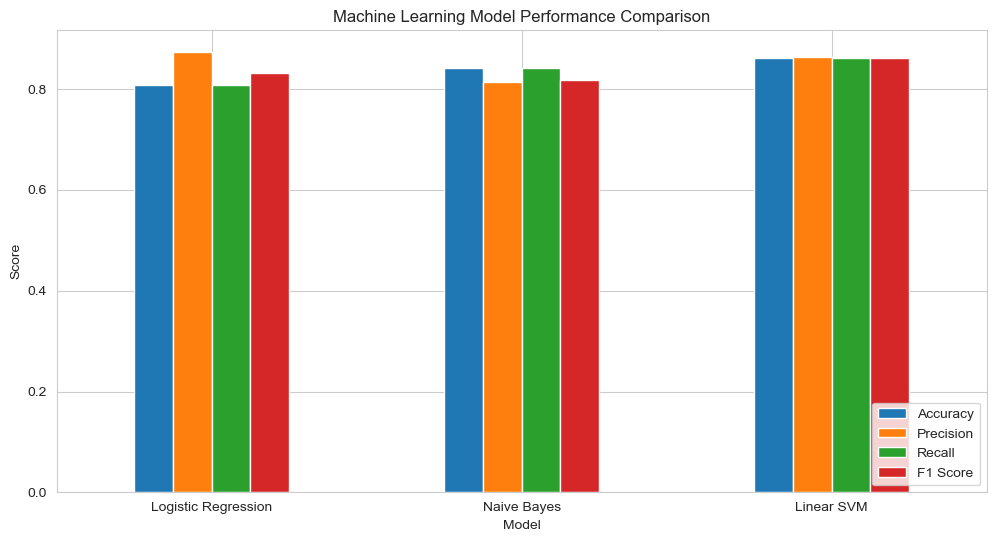

In [69]:
# Visualize model comparison
model_results.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [70]:
# Select the best model 
best_model_name = model_results.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Linear SVM


In [72]:
# Classification report
from sklearn.metrics import classification_report

y_pred = best_model.predict(X_test_tfidf)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Negative       0.81      0.83      0.82     16980
     Neutral       0.41      0.45      0.43      5537
    Positive       0.94      0.92      0.93     47424

    accuracy                           0.86     69941
   macro avg       0.72      0.73      0.73     69941
weighted avg       0.86      0.86      0.86     69941



#### Common Customer Issues Detection

In [ ]:
""" We want to discover what customers complain about most.
  We will use:TF-IDF,NMF Topic Modelling,Negative customer reviews"""

In [73]:
# Extract negative reviews
negative_reviews = data[
    data['Sentiment'] == 'Negative'
].copy()

print("Total Negative Reviews:", len(negative_reviews))

Total Negative Reviews: 84900


In [74]:
# Import topic modelling libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

In [75]:
# Convert reviews into TF-IDF features
issue_vectorizer = TfidfVectorizer(
    max_features=10000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2),
    stop_words='english'
)

X_negative = issue_vectorizer.fit_transform(
    negative_reviews['Clean_Reviews']
)

In [76]:
# Apply NMF
nmf_model = NMF(
    n_components=8,
    random_state=42,
    max_iter=300
)

topic_matrix = nmf_model.fit_transform(X_negative)

In [77]:
# Display common issues
terms = issue_vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(nmf_model.components_):

    top_words = [
        terms[i]
        for i in topic.argsort()[:-11:-1]
    ]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")

Topic 1: phone, battery, screen, new, problem, time, use, day, charge, bought
Topic 2: work, didnt, didnt work, doesnt, doesnt work, phone work, phone didnt, work properly, phone doesnt, properly
Topic 3: good, good phone, phone good, work good, product, good product, good condition, condition, battery, really
Topic 4: sim, card, sim card, slot, read, dual, read sim, dual sim, use, tmobile
Topic 5: bad, bad phone, bad bad, really bad, battery, product, really, phone bad, bad product, quality
Topic 6: working, stopped, stopped working, month, working month, week, stop working, stop, working week, phone stopped
Topic 7: dont, buy, dont buy, money, waste, waste money, buy phone, like, dont waste, product
Topic 8: unlocked, phone unlocked, locked, unlocked phone, att, verizon, phone, unlock, use, factory unlocked


In [79]:
# Identify dominant topic for each review
negative_reviews['Dominant_Topic'] = topic_matrix.argmax(axis=1)

display(
    negative_reviews[
        ['Product Name', 'Brand Name', 'Rating', 'Reviews', 'Dominant_Topic']
    ].head(10)
)

,Product Name,Brand Name,Rating,Reviews,Dominant_Topic
5,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,1,I already had a phone with problems... I know ...,2
6,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,2,The charging port was loose. I got that solder...,0
7,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,2,"Phone looks good but wouldn't stay charged, ha...",6
13,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,1,I'm really disappointed about my phone and ser...,0
15,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,2,Had this phone before and loved it but was not...,3
22,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,1,I purchased this phone in December as a christ...,0
28,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,1,was not in good condition but does work good,2
29,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,1,Just... not good. The phone has great screen r...,2
32,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,2,One of the phones have a bad charger port. I w...,4
42,"""Nokia Asha 302 Unlocked GSM Phone with 3.2MP ...",Nokia,2,I like these phone I bought it for my mom and ...,0


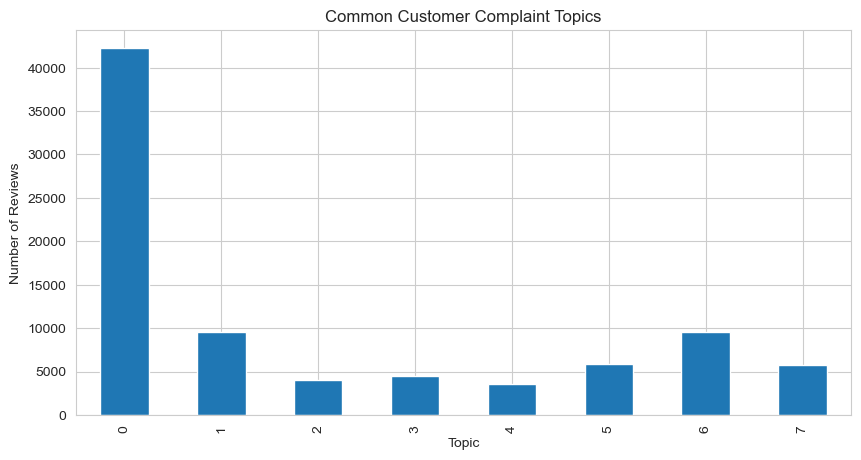

In [80]:
# Count complaints by topic
topic_counts = negative_reviews['Dominant_Topic'].value_counts().sort_index()

topic_counts.plot(kind='bar', figsize=(10, 5))

plt.title('Common Customer Complaint Topics')
plt.xlabel('Topic')
plt.ylabel('Number of Reviews')
plt.show()

#### Customer Satisfaction Analysis

In [81]:
# Calculate sentiment percentages
sentiment_distribution = data['Sentiment'].value_counts(normalize=True) * 100

display(sentiment_distribution)

Sentiment
Positive    67.805916
Negative    24.277675
Neutral      7.916409
Name: proportion, dtype: float64

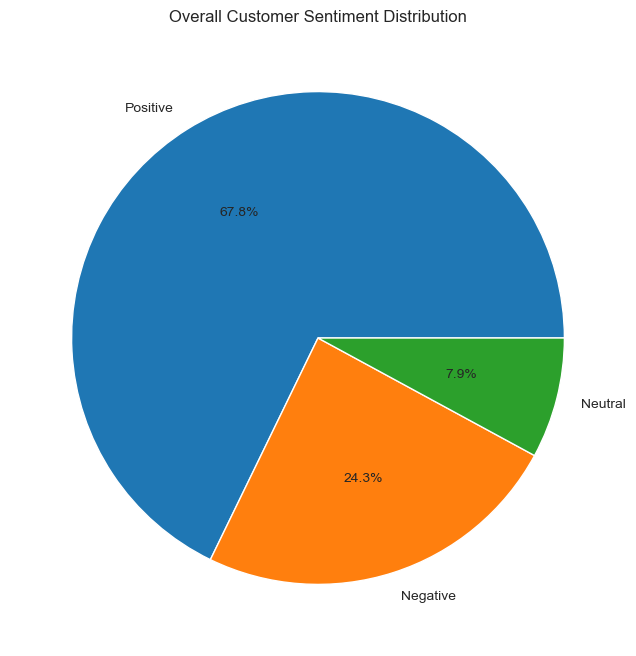

In [82]:
# Sentiment visualization
sentiment_distribution.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(8, 8)
)

plt.title('Overall Customer Sentiment Distribution')
plt.ylabel('')
plt.show()

In [83]:
# Brand-wise customer satisfaction
brand_satisfaction = data.groupby('Brand Name').agg(
    Total_Reviews=('Reviews', 'count'),
    Average_Rating=('Rating', 'mean'),
    Positive_Reviews=('Sentiment', lambda x: (x == 'Positive').sum()),
    Negative_Reviews=('Sentiment', lambda x: (x == 'Negative').sum()),
    Neutral_Reviews=('Sentiment', lambda x: (x == 'Neutral').sum())
).reset_index()

brand_satisfaction['Positive_Percentage'] = (
    brand_satisfaction['Positive_Reviews'] /
    brand_satisfaction['Total_Reviews'] * 100
)

brand_satisfaction['Negative_Percentage'] = (
    brand_satisfaction['Negative_Reviews'] /
    brand_satisfaction['Total_Reviews'] * 100
)

display(
    brand_satisfaction.sort_values(
        by='Positive_Percentage',
        ascending=False
    ).head(15)
)

,Brand Name,Total_Reviews,Average_Rating,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Positive_Percentage,Negative_Percentage
355,iPartsBuy,2,5.0,2,0,0,100.0,0.0
354,iNew,6,5.0,6,0,0,100.0,0.0
29,Bluboo,4,5.0,4,0,0,100.0,0.0
345,bbfone,2,4.5,2,0,0,100.0,0.0
343,apple,1,4.0,1,0,0,100.0,0.0
317,VIP,1,5.0,1,0,0,100.0,0.0
299,Tivax,2,4.5,2,0,0,100.0,0.0
301,TracFone,1,5.0,1,0,0,100.0,0.0
280,Spicy World,2,5.0,2,0,0,100.0,0.0
296,ThL,1,4.0,1,0,0,100.0,0.0


In [84]:
# Identify brands with the highest negative feedback
top_negative_brands = brand_satisfaction.sort_values(
    by='Negative_Percentage',
    ascending=False
)

display(top_negative_brands.head(10))

,Brand Name,Total_Reviews,Average_Rating,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Positive_Percentage,Negative_Percentage
367,nokia,2,1.000000,0,2,0,0.0,100.0
51,Conquest S8 Pro 3GB Smartphone (Black),1,1.000000,0,1,0,0.0,100.0
50,Concox,1,1.000000,0,1,0,0.0,100.0
54,Crony,6,1.333333,0,6,0,0.0,100.0
325,Vostrostone,1,2.000000,0,1,0,0.0,100.0
336,Yezz Wireless Ltd.,2,1.000000,0,2,0,0.0,100.0
321,Vernee,1,1.000000,0,1,0,0.0,100.0
331,Wool,2,1.500000,0,2,0,0.0,100.0
122,Ipro,2,2.000000,0,2,0,0.0,100.0
103,HJ Wireless,6,1.000000,0,6,0,0.0,100.0


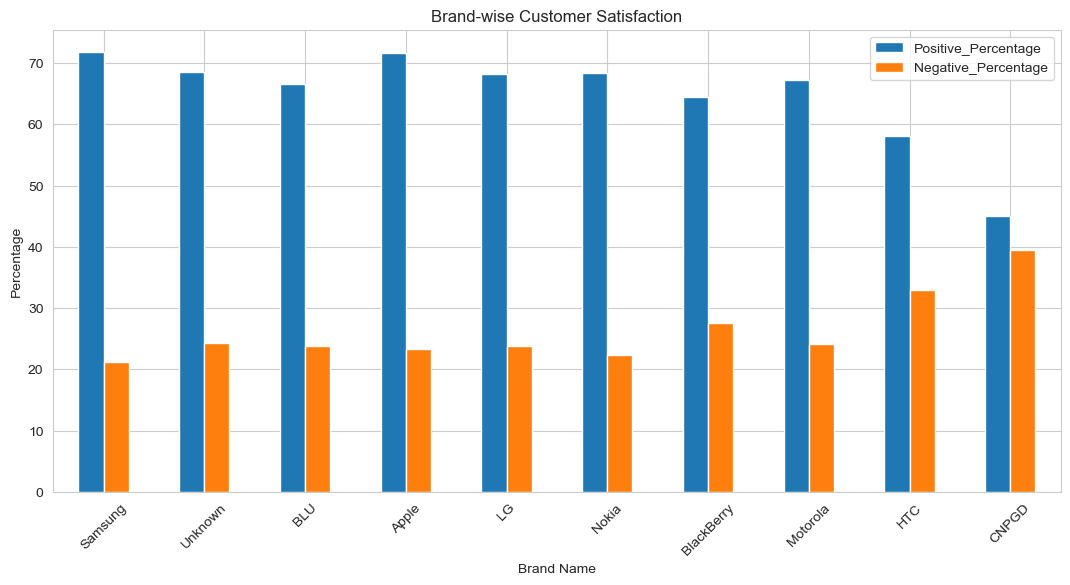

In [85]:
# Visualize customer satisfaction
top_brands_satisfaction = brand_satisfaction.nlargest(
    10, 'Total_Reviews'
)

top_brands_satisfaction.plot(
    x='Brand Name',
    y=['Positive_Percentage', 'Negative_Percentage'],
    kind='bar',
    figsize=(13, 6)
)

plt.title('Brand-wise Customer Satisfaction')
plt.ylabel('Percentage')
plt.xticks(rotation=45)
plt.show()

In [87]:
# Best Mobile Phone Recommendation System
"""This is one of the most important parts of our project.
We will rank phones using customer ratings, sentiment and review volume."""

In [88]:
phone_analysis = data.groupby(
    ['Product Name', 'Brand Name']
).agg(
    Total_Reviews=('Rating', 'count'),
    Average_Rating=('Rating', 'mean'),
    Average_Price=('Price', 'mean'),
    Positive_Reviews=('Sentiment', lambda x: (x == 'Positive').sum()),
    Negative_Reviews=('Sentiment', lambda x: (x == 'Negative').sum()),
    Neutral_Reviews=('Sentiment', lambda x: (x == 'Neutral').sum())
).reset_index()

In [90]:
# Calculate sentiment percentages
phone_analysis['Positive_Percentage'] = (
    phone_analysis['Positive_Reviews'] /
    phone_analysis['Total_Reviews'] * 100
)

phone_analysis['Negative_Percentage'] = (
    phone_analysis['Negative_Reviews'] /
    phone_analysis['Total_Reviews'] * 100
)

phone_analysis['Neutral_Percentage'] = (
    phone_analysis['Neutral_Reviews'] /
    phone_analysis['Total_Reviews'] * 100
)

In [91]:
# Calculate Bayesian rating
global_rating = data['Rating'].mean()

minimum_reviews = phone_analysis['Total_Reviews'].quantile(0.50)

phone_analysis['Bayesian_Rating'] = (
    (phone_analysis['Total_Reviews'] /
     (phone_analysis['Total_Reviews'] + minimum_reviews))
    * phone_analysis['Average_Rating']
    +
    (minimum_reviews /
     (phone_analysis['Total_Reviews'] + minimum_reviews))
    * global_rating
)

In [92]:
# Normalize scores
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

phone_analysis[['Rating_Score', 'Review_Score']] = scaler.fit_transform(
    phone_analysis[['Bayesian_Rating', 'Total_Reviews']]
)

phone_analysis['Positive_Score'] = (
    phone_analysis['Positive_Percentage'] / 100
)

phone_analysis['Negative_Score'] = (
    phone_analysis['Negative_Percentage'] / 100
)

In [93]:
# Calculate recommendation score
phone_analysis['Recommendation_Score'] = (

    phone_analysis['Rating_Score'] * 0.50 +

    phone_analysis['Positive_Score'] * 0.30 +

    phone_analysis['Review_Score'] * 0.10 +

    (1 - phone_analysis['Negative_Score']) * 0.10

)

In [94]:
# Filter reliable products
recommended_phones = phone_analysis[
    phone_analysis['Total_Reviews'] >= 20
].copy()

recommended_phones = recommended_phones.sort_values(
    by='Recommendation_Score',
    ascending=False
)

In [95]:
# Display top 10 recommended phones
display(
    recommended_phones[
        [
            'Product Name',
            'Brand Name',
            'Average_Price',
            'Total_Reviews',
            'Average_Rating',
            'Positive_Percentage',
            'Negative_Percentage',
            'Recommendation_Score'
        ]
    ].head(10)
)

,Product Name,Brand Name,Average_Price,Total_Reviews,Average_Rating,Positive_Percentage,Negative_Percentage,Recommendation_Score
2782,OtterBox Protective Defender Case for Apple iP...,OtterBox,27.49,396,4.585859,89.898990,4.797980,0.905288
1573,Huawei Mate 2 - Factory Unlocked (Black),Huawei,229.99,787,4.439644,87.039390,9.148666,0.903678
2796,Otterbox Otterbox Defender Carrying Case for S...,OtterBox,14.99,602,4.508306,88.205980,8.305648,0.903233
2758,OtterBox 77-29864 Defender Series Hybrid Case ...,OtterBox,9.99,641,4.478939,87.207488,7.800312,0.898543
2300,Motorola Moto E (1st Generation) - Black - 4 G...,Motorola,89.99,778,4.394602,86.760925,8.611825,0.892478
147,Apple Watch (42MM) Stainless Steel Case with B...,Apple,775.00,27,4.962963,100.000000,0.000000,0.892218
2299,Motorola Moto E (1st Generation) - Black - 4 G...,Motorola,109.99,795,4.378616,86.415094,8.805031,0.889516
2788,OtterBox SYMMETRY SERIES Case for iPhone 6 Plu...,OtterBox,15.99,409,4.533007,88.508557,6.601467,0.889421
2754,OtterBox 'Defender Series' Rugged and Protecti...,OtterBox,16.90,273,4.553114,89.377289,5.494505,0.880325
2752,OtterBox 'Defender Series' Rugged Case for Sam...,OtterBox,24.90,152,4.605263,90.789474,3.947368,0.877012


### Product Team Improvement Insights

In [96]:
# Finally, let's generate actionable business insights.
# Identify products with high negative feedback
problematic_products = phone_analysis[
    (phone_analysis['Total_Reviews'] >= 20)
].sort_values(
    by='Negative_Percentage',
    ascending=False
)

display(
    problematic_products[
        [
            'Product Name',
            'Brand Name',
            'Total_Reviews',
            'Average_Rating',
            'Negative_Percentage'
        ]
    ].head(10)
)

,Product Name,Brand Name,Total_Reviews,Average_Rating,Negative_Percentage
2433,"NOTE3-Style 5.7"" 3G Android 4.2 Smartphone(Dua...",Unknown,40,1.800000,80.000000
2350,Motorola RAZR V3 Unlocked Phone with Camera an...,Motorola,25,2.000000,76.000000
1677,Indigi V13WH-CP09 Factory Unlocked 5.5in Andro...,Indigi,28,2.071429,71.428571
1498,HTC myTouch 4G Slide Global QWERTY Unlocked GS...,HTC,21,2.095238,71.428571
48,"6"" Inch Unlocked Android 4.4.2 MTK6572 Dual Co...",Unknown,108,2.120370,70.370370
1690,Indigi® Unlocked Indigi 5.5-inch Dual-Core 3G ...,Indigi,20,2.150000,70.000000
4364,i9300 Dual SIM Cell Phone Quad Band 4.0 inch H...,px phone,73,2.109589,69.863014
3060,SODIAL Unlocked Quadband Dual Sim Android 4.2 ...,Unlocked Cell Phone,98,2.112245,69.387755
2862,"Padgene New Version Vogue 6"" Android 5.1 Unloc...",Padgene,35,2.028571,68.571429
4381,indigi V5 Unlocked Android 4.2 JB 3G Smartphon...,indigi,25,2.200000,68.000000


In [97]:
# Compare best and worst products
print("TOP 5 RECOMMENDED PHONES")

display(recommended_phones.head(5))

print("TOP 5 PRODUCTS NEEDING ATTENTION")

display(problematic_products.head(5))

TOP 5 RECOMMENDED PHONES


,Product Name,Brand Name,Total_Reviews,Average_Rating,Average_Price,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Positive_Percentage,Negative_Percentage,Neutral_Percentage,Bayesian_Rating,Rating_Score,Review_Score,Positive_Score,Negative_Score,Recommendation_Score
2782,OtterBox Protective Defender Case for Apple iP...,OtterBox,396,4.585859,27.49,356,19,21,89.898990,4.797980,5.303030,4.552748,1.000000,0.403885,0.898990,0.047980,0.905288
1573,Huawei Mate 2 - Factory Unlocked (Black),Huawei,787,4.439644,229.99,685,72,30,87.039390,9.148666,3.811944,4.425727,0.942681,0.803681,0.870394,0.091487,0.903678
2796,Otterbox Otterbox Defender Carrying Case for S...,OtterBox,602,4.508306,14.99,531,50,21,88.205980,8.305648,3.488372,4.488344,0.970937,0.614519,0.882060,0.083056,0.903233
2758,OtterBox 77-29864 Defender Series Hybrid Case ...,OtterBox,641,4.478939,9.99,559,50,32,87.207488,7.800312,4.992200,4.460919,0.958561,0.654397,0.872075,0.078003,0.898543
2300,Motorola Moto E (1st Generation) - Black - 4 G...,Motorola,778,4.394602,89.99,675,67,36,86.760925,8.611825,4.627249,4.381490,0.922718,0.794479,0.867609,0.086118,0.892478


TOP 5 PRODUCTS NEEDING ATTENTION


,Product Name,Brand Name,Total_Reviews,Average_Rating,Average_Price,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Positive_Percentage,Negative_Percentage,Neutral_Percentage,Bayesian_Rating,Rating_Score,Review_Score,Positive_Score,Negative_Score,Recommendation_Score
2433,"NOTE3-Style 5.7"" 3G Android 4.2 Smartphone(Dua...",Unknown,40,1.800000,149.99,6,32,2,15.000000,80.000000,5.000000,2.390962,0.024473,0.039877,0.150000,0.800000,0.081224
2350,Motorola RAZR V3 Unlocked Phone with Camera an...,Motorola,25,2.000000,134.10,4,19,2,16.000000,76.000000,8.000000,2.721068,0.173436,0.024540,0.160000,0.760000,0.161172
1677,Indigi V13WH-CP09 Factory Unlocked 5.5in Andro...,Indigi,28,2.071429,109.99,5,20,3,17.857143,71.428571,10.714286,2.717441,0.171800,0.027607,0.178571,0.714286,0.170803
1498,HTC myTouch 4G Slide Global QWERTY Unlocked GS...,HTC,21,2.095238,199.99,5,15,1,23.809524,71.428571,4.761905,2.849601,0.231438,0.020450,0.238095,0.714286,0.217764
48,"6"" Inch Unlocked Android 4.4.2 MTK6572 Dual Co...",Unknown,108,2.120370,100.00,29,76,3,26.851852,70.370370,2.777778,2.346279,0.004309,0.109407,0.268519,0.703704,0.123280


In [98]:
# Export final results
recommended_phones.to_csv(
    'Best_Mobile_Phone_Recommendations.csv',
    index=False
)

brand_satisfaction.to_csv(
    'Brand_Customer_Satisfaction.csv',
    index=False
)

problematic_products.to_csv(
    'Products_Needing_Improvement.csv',
    index=False
)

print("All analysis results exported successfully!")

All analysis results exported successfully!


### Save and Export Models

In [99]:
import joblib
import os
# Create model directory
os.makedirs('models', exist_ok=True)

['models/best_sentiment_model.pkl']

In [100]:
# Save the best sentiment model
joblib.dump(
    best_model,
    'models/best_sentiment_model.pkl'
)
# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    'models/tfidf_vectorizer.pkl'
)
# Save NMF topic model
joblib.dump(
    nmf_model,
    'models/nmf_topic_model.pkl'
)
# Save issue vectorizer
joblib.dump(
    issue_vectorizer,
    'models/issue_vectorizer.pkl'
)
# Save recommendation data
phone_analysis.to_csv(
    'models/phone_recommendations.csv',
    index=False
)
# Save customer satisfaction data
brand_satisfaction.to_csv(
    'models/brand_satisfaction.csv',
    index=False
)
# Save issue analysis
problematic_products.to_csv(
    'models/problematic_products.csv',
    index=False
)


#### Test Model Loading

In [101]:
# Load sentiment model
loaded_model = joblib.load(
    'models/best_sentiment_model.pkl'
)
# Load TF-IDF vectorizer
loaded_vectorizer = joblib.load(
    'models/tfidf_vectorizer.pkl'
)

In [102]:
# Test sentiment prediction
review = ["The battery performance is excellent"]

review_vector = loaded_vectorizer.transform(review)

prediction = loaded_model.predict(review_vector)

print("Predicted Sentiment:", prediction[0])

Predicted Sentiment: Positive


In [103]:
# Load NMF model
loaded_nmf = joblib.load(
    'models/nmf_topic_model.pkl'
)
# Load issue vectorizer
loaded_issue_vectorizer = joblib.load(
    'models/issue_vectorizer.pkl'
)

In [104]:
# Verify saved files
print("Saved Model Files:")

for file in os.listdir('models'):
    print(file)

Saved Model Files:
best_sentiment_model.pkl
brand_satisfaction.csv
issue_vectorizer.pkl
nmf_topic_model.pkl
phone_recommendations.csv
problematic_products.csv
tfidf_vectorizer.pkl
